In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob

In [2]:
data_paths = np.array(glob('./high_speed_trajectories/**/*.csv'))
data_paths

array(['./high_speed_trajectories/YV4228/2026_05_27_Stack5_SIM²_Cell24.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack5_SIM²_Cell25.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack5_SIM²_Cell22.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack8_SIM²_Cell29.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack5_SIM²_Cell23.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack5_SIM²_Cell21.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack7_SIM²_Cell28.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack2_SIM²_Cell9.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack2_SIM²_Cell8.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack4_SIM²_Cell20.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack4_SIM²_Cell19.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack4_SIM²_Cell17.csv',
       './high_speed_trajectories/YV4228/2026_05_27_Stack3_SIM²_Cell13.csv',
 

In [3]:
dfs = [pd.read_csv(path) for path in data_paths if 'YV4228' in path]
short_df = [pd.read_csv(path) for path in data_paths if 'YV4235' in path]
dfs[0]

,Centromere Separation (um),Spindle Length (um),Time (sec),Tension Classification
0,0.477684,0.996300,0,Low Tension
1,0.466693,1.035953,5,Low Tension
2,0.402723,0.994824,10,Low Tension
3,0.348529,1.030936,15,Low Tension
4,0.469573,1.018321,20,Low Tension
...,...,...,...,...
56,0.514727,1.407603,280,Low Tension
57,0.703946,1.375798,285,High Tension
58,0.526529,1.211941,290,Low Tension
59,0.458137,1.380599,295,Low Tension


In [4]:
from hmmlearn import hmm

# Default HMM parameters — 3 hidden states corresponding to tension levels.
# State order: 0 = No Tension, 1 = Low Tension, 2 = High Tension
DEFAULT_EMISSION_MEANS = np.array([[0.1], [0.35], [0.7]])        # Gaussian means per state (um)
DEFAULT_EMISSION_COVARS = np.array([0.05, 0.2, 0.5])           # Gaussian variances per state (n_states,)

# ── Single tunable parameter ──────────────────────────────────────────────
# Self-transition probability p. Everything else in the transition matrix
# is derived from this one value.
#
# For a self-transition probability p and adjacent transition q, the Viterbi
# algorithm switches states when the emission likelihood ratio R = b_j(x)/b_i(x)
# exceeds p/q for a single observation, or sqrt(p/q) for two consecutive ones.
#
#   1 obs stays  when: R < p/q
#   2 obs switch when: R > sqrt(p/q)
#
# p = 0.70 → p/q ≈ 2.4,  sqrt(p/q) ≈ 1.55
# → A single timepoint up to ~2.4× more likely in another state won't switch,
#   but 2 consecutive observations at ~1.6× or more will switch.
SELF_TRANSITION_P = 0.50

def build_transmat(p, n_states=3, jump_prob=0.1):
    """Build a row-stochastic transition matrix from a single self-transition
    probability *p*.

    Each row gives probability *p* to staying, *jump_prob* to each non-adjacent
    state, and distributes the remainder equally among adjacent neighbours.
    """
    mat = np.full((n_states, n_states), 0.0)
    for i in range(n_states):
        mat[i, i] = p
        # Identify adjacent and non-adjacent states
        adjacent = [j for j in range(n_states) if j != i and abs(j - i) == 1]
        non_adjacent = [j for j in range(n_states) if j != i and abs(j - i) > 1]
        # Assign jump_prob to each non-adjacent state
        for j in non_adjacent:
            mat[i, j] = jump_prob
        # Remainder split equally among adjacent neighbours
        remainder = 1.0 - p - jump_prob * len(non_adjacent)
        q = remainder / len(adjacent) if adjacent else 0.0
        for j in adjacent:
            mat[i, j] = q
    return mat

DEFAULT_TRANSMAT = build_transmat(SELF_TRANSITION_P)
DEFAULT_STARTPROB = np.array([0.6, 0.3, 0.1])                    # Initial state probabilities

STATE_LABELS = ['No Tension', 'Low Tension', 'High Tension']

def annotate_data_trajectory(
    df,
    column='Centromere Separation (um)',
    means=DEFAULT_EMISSION_MEANS,
    covars=DEFAULT_EMISSION_COVARS,
    transmat=DEFAULT_TRANSMAT,
    startprob=DEFAULT_STARTPROB,
    n_iter=100,
    random_state=42,
):
    """Annotate a trajectory with tension-state labels using a Gaussian HMM.

    Parameters
    ----------
    df : pd.DataFrame
        Trajectory data containing the separation column.
    column : str
        Column to use as the HMM emission observation.
    means : array-like, shape (n_states, 1)
        Initial means of the Gaussian emission distributions.
    covars : array-like, shape (n_states,) or (n_states, 1, 1)
        Initial variances of the Gaussian emission distributions.
    transmat : array-like, shape (n_states, n_states)
        Transition probability matrix (row-stochastic).
    startprob : array-like, shape (n_states,)
        Initial state probabilities.
    n_iter : int
        Maximum number of EM iterations.
    random_state : int
        Random seed for reproducibility.

    Returns
    -------
    pd.DataFrame
        Copy of *df* with a ``Tension Classification`` column of state labels
        and a ``HMM State`` column of integer state indices.
    """
    n_states = len(means)
    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type='diag',
        n_iter=n_iter,
        random_state=random_state,
        init_params='',     # Don't auto-initialize anything — we set all params manually
        params='',           # Don't update any params — just decode states with the given model
    )
    model.means_ = np.array(means, dtype=float).reshape(n_states, 1)
    model.covars_ = np.array(covars, dtype=float).reshape(n_states, 1)
    model.transmat_ = np.array(transmat, dtype=float)
    model.startprob_ = np.array(startprob, dtype=float)

    # Drop rows with NaN in the observation column so the HMM can decode.
    valid_mask = df[column].notna()
    X = df.loc[valid_mask, [column]].values.astype(float)
    states = model.predict(X)

    new_df = df.copy()
    new_df['HMM State'] = np.nan
    new_df.loc[valid_mask, 'HMM State'] = states
    new_df['Tension Classification'] = new_df['HMM State'].apply(
        lambda s: STATE_LABELS[int(s)] if pd.notna(s) else np.nan
    )
    return new_df

processed_dfs = [annotate_data_trajectory(df) for df in dfs]
processed_short_dfs = [annotate_data_trajectory(df) for df in short_df]

In [5]:
tdf = processed_dfs[10]
tdf

,Centromere Separation (um),Spindle Length (um),Time (sec),Tension Classification,HMM State
0,0.731818,1.479204,0,Low Tension,1.0
1,0.066435,1.410977,5,No Tension,0.0
2,0.003432,1.703111,10,No Tension,0.0
3,0.996910,1.729105,15,Low Tension,1.0
4,0.155008,1.529452,20,No Tension,0.0
...,...,...,...,...,...
56,0.161703,1.541986,280,No Tension,0.0
57,0.437793,1.533862,285,Low Tension,1.0
58,0.453148,1.654034,290,Low Tension,1.0
59,0.489996,1.491267,295,Low Tension,1.0


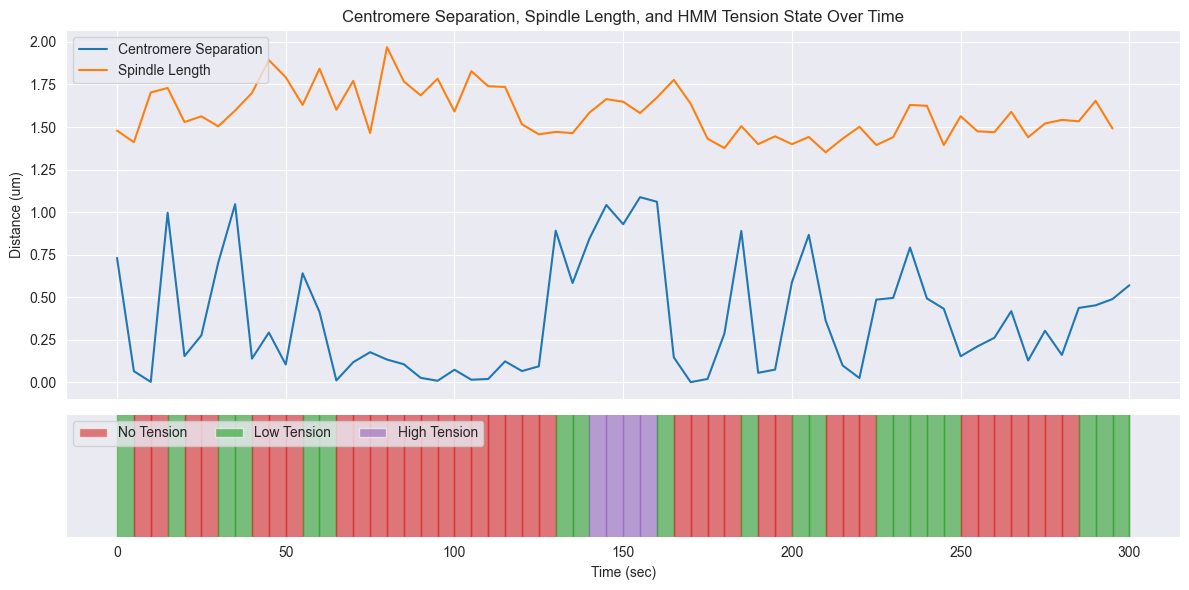

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# Top axis: centromere separation and spindle length over time
ax1.plot(tdf['Time (sec)'], tdf['Centromere Separation (um)'], label='Centromere Separation', color='tab:blue')
ax1.plot(tdf['Time (sec)'], tdf['Spindle Length (um)'], label='Spindle Length', color='tab:orange')
ax1.set_ylabel('Distance (um)')
ax1.legend(loc='upper left')
ax1.set_title('Centromere Separation, Spindle Length, and HMM Tension State Over Time')

# Bottom axis: state timeline as colored spans
state_colors = {'No Tension': 'tab:red', 'Low Tension': 'tab:green', 'High Tension': 'tab:purple'}
times = tdf['Time (sec)'].values
states = tdf['Tension Classification'].values

for i in range(len(states)):
    if pd.isna(states[i]):
        continue
    color = state_colors[states[i]]
    if i < len(states) - 1 and not pd.isna(states[i + 1]):
        ax2.axvspan(times[i], times[i + 1], alpha=0.6, color=color)
    else:
        ax2.axvspan(times[i], times[i], alpha=0.6, color=color)

ax2.set_yticks([])
ax2.set_xlabel('Time (sec)')

# Add a legend for the state colors
from matplotlib.patches import Patch
state_legend = [Patch(facecolor=color, label=label, alpha=0.6) for label, color in state_colors.items()]
ax2.legend(handles=state_legend, loc='upper left', ncol=3)

plt.tight_layout()
plt.show()

In [7]:
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Patch

state_colors = {'No Tension': 'tab:red', 'Low Tension': 'tab:green', 'High Tension': 'tab:purple'}

def plot_trajectory(df, ax1, ax2):
    """Plot centromere separation, spindle length, and HMM state timeline."""
    times = df['Time (sec)'].values
    states = df['Tension Classification'].values

    ax1.plot(times, df['Centromere Separation (um)'], label='Centromere Separation', color='tab:blue')
    ax1.plot(times, df['Spindle Length (um)'], label='Spindle Length', color='tab:orange')
    ax1.set_ylabel('Distance (um)')
    ax1.legend(loc='upper left')

    for i in range(len(states)):
        if pd.isna(states[i]):
            continue
        color = state_colors[states[i]]
        if i < len(states) - 1 and not pd.isna(states[i + 1]):
            ax2.axvspan(times[i], times[i + 1], alpha=0.6, color=color)
        else:
            ax2.axvspan(times[i], times[i], alpha=0.6, color=color)

    ax2.set_yticks([])
    ax2.set_xlabel('Time (sec)')
    state_legend = [Patch(facecolor=color, label=label, alpha=0.6) for label, color in state_colors.items()]
    ax2.legend(handles=state_legend, loc='upper left', ncol=3)

with PdfPages('high_speed_output/trajectory_plots.pdf') as pdf:
    for idx, df in enumerate(processed_dfs):
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
        title = f'Trajectory {idx} — Centromere Separation, Spindle Length, and HMM Tension State'
        ax1.set_title(title)
        plot_trajectory(df, ax1, ax2)
        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

print(f'Saved {len(processed_dfs)} trajectory plots to high_speed_output/trajectory_plots.pdf') 

Saved 26 trajectory plots to high_speed_output/trajectory_plots.pdf


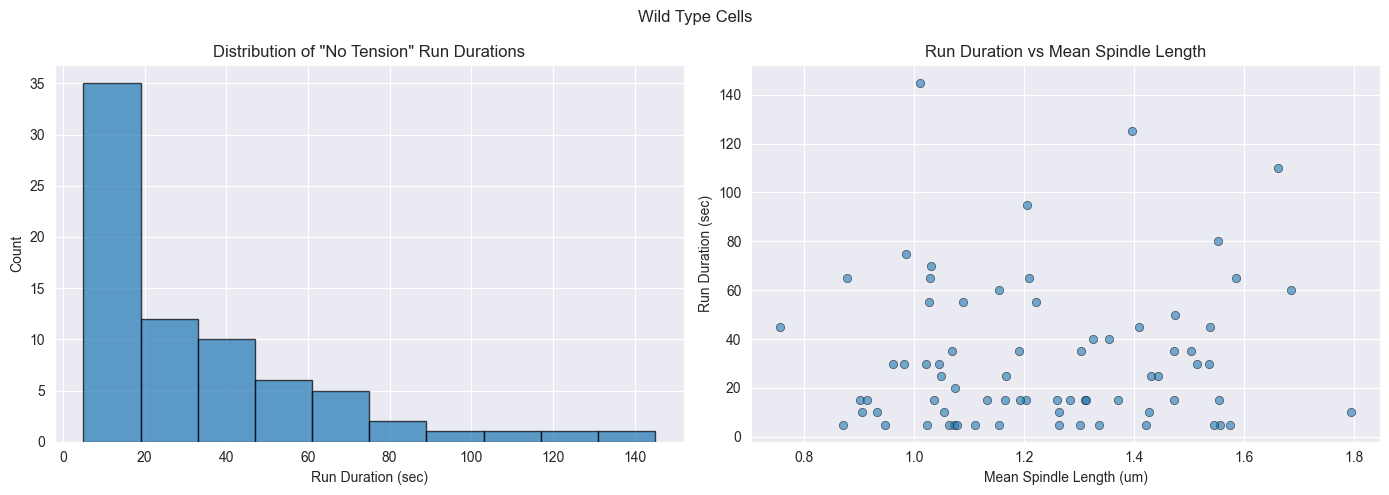

In [8]:
def extract_no_tension_runs(processed_dfs, state_col='Tension Classification', spindle_col='Spindle Length (um)', time_col='Time (sec)'):
    """Find continuous runs of 'No Tension' that don't touch the start or end
    of a trajectory.

    Returns a DataFrame with columns: run_duration_sec, mean_spindle_length.
    """
    records = []
    for df in processed_dfs:
        states = df[state_col].values
        spindle = df[spindle_col].values
        times = df[time_col].values
        n = len(states)

        # Find indices where state is 'No Tension'
        is_no_tension = np.array([s == 'No Tension' if pd.notna(s) else False for s in states])

        # Find run boundaries
        i = 0
        while i < n:
            if not is_no_tension[i]:
                i += 1
                continue
            # Start of a run
            start = i
            while i < n and is_no_tension[i]:
                i += 1
            end = i  # exclusive
            # Skip runs that touch the beginning or end of the timeline
            if start == 0 or end == n:
                continue
            # Duration in seconds using the Time column
            run_duration = times[end - 1] - times[start]
            run_spindle = spindle[start:end]
            run_spindle = run_spindle[~pd.isna(run_spindle)]
            mean_spindle = np.mean(run_spindle) if len(run_spindle) > 0 else np.nan
            records.append({'run_duration_sec': run_duration, 'mean_spindle_length': mean_spindle})

    return pd.DataFrame(records)

run_df = extract_no_tension_runs(processed_dfs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribution of run durations
ax1.hist(run_df['run_duration_sec'], edgecolor='black', alpha=0.7)
ax1.set_xlabel('Run Duration (sec)')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of "No Tension" Run Durations')

# Plot 2: Run duration vs mean spindle length
ax2.scatter(run_df['mean_spindle_length'], run_df['run_duration_sec'], alpha=0.6, edgecolors='black', linewidths=0.5)
ax2.set_ylabel('Run Duration (sec)')
ax2.set_xlabel('Mean Spindle Length (um)')
ax2.set_title('Run Duration vs Mean Spindle Length')
plt.suptitle('Wild Type Cells')
plt.tight_layout()
plt.show()

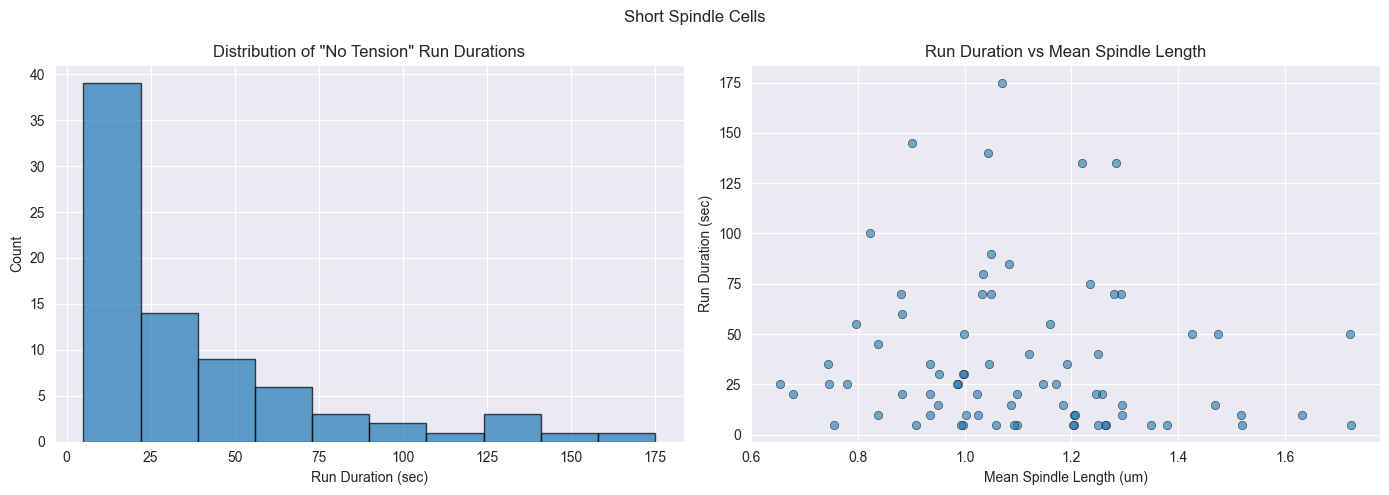

In [9]:
short_run_df = extract_no_tension_runs(processed_short_dfs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribution of run durations
ax1.hist(short_run_df['run_duration_sec'], edgecolor='black', alpha=0.7)
ax1.set_xlabel('Run Duration (sec)')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of "No Tension" Run Durations')

# Plot 2: Run duration vs mean spindle length
ax2.scatter(short_run_df['mean_spindle_length'], short_run_df['run_duration_sec'], alpha=0.6, edgecolors='black', linewidths=0.5)
ax2.set_ylabel('Run Duration (sec)')
ax2.set_xlabel('Mean Spindle Length (um)')
ax2.set_title('Run Duration vs Mean Spindle Length')
plt.suptitle('Short Spindle Cells')
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import pearsonr
run_df = extract_no_tension_runs(processed_dfs).dropna(subset=['mean_spindle_length', 'run_duration_sec'])
pearsonr(run_df['mean_spindle_length'], run_df['run_duration_sec'])

PearsonRResult(statistic=np.float64(0.05933544948394703), pvalue=np.float64(0.6180245979595548))

In [11]:
from scipy.stats import pearsonr
short_run_df = extract_no_tension_runs(processed_short_dfs).dropna(subset=['mean_spindle_length', 'run_duration_sec'])
pearsonr(short_run_df['mean_spindle_length'], short_run_df['run_duration_sec'])

PearsonRResult(statistic=np.float64(-0.09695258091660156), pvalue=np.float64(0.40474864615527173))

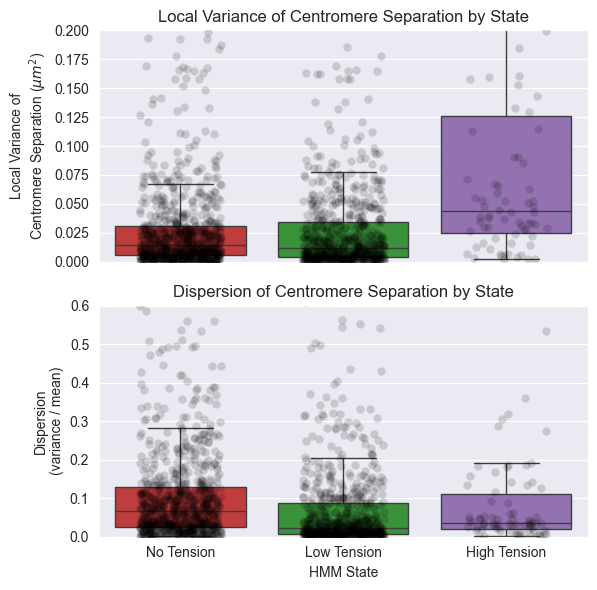

In [12]:
def compute_local_variance_and_dispersion_by_state(
    processed_dfs,
    value_col='Centromere Separation (um)',
    state_col='Tension Classification',
    time_col='Time (sec)',
    window=5,
    min_periods=3,
):
    """Compute rolling local variance and dispersion of centromere separation."""
    records = []
    for trajectory_idx, df in enumerate(processed_dfs):
        rolling_mean = df[value_col].rolling(
            window=window,
            center=True,
            min_periods=min_periods,
        ).mean()
        rolling_var = df[value_col].rolling(
            window=window,
            center=True,
            min_periods=min_periods,
        ).var()
        rolling_dispersion = rolling_var / rolling_mean

        valid_mask = rolling_var.notna() & rolling_mean.notna() & df[state_col].notna()
        for state in STATE_LABELS:
            state_mask = valid_mask & (df[state_col] == state)
            if not state_mask.any():
                continue
            records.extend(
                {
                    'trajectory': trajectory_idx,
                    'time_sec': time,
                    'state': state,
                    'local_variance': variance,
                    'dispersion': dispersion,
                }
                for time, variance, dispersion in zip(
                    df.loc[state_mask, time_col],
                    rolling_var.loc[state_mask],
                    rolling_dispersion.loc[state_mask],
                )
            )

    return pd.DataFrame(records)

analysis_df = compute_local_variance_and_dispersion_by_state(processed_dfs)
state_palette = {'No Tension': 'tab:red', 'Low Tension': 'tab:green', 'High Tension': 'tab:purple'}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True)

sns.boxplot(
    data=analysis_df,
    x='state',
    y='local_variance',
    hue='state',
    order=STATE_LABELS,
    hue_order=STATE_LABELS,
    palette=state_palette,
    dodge=False,
    showfliers=False,
    ax=ax1,
)
if ax1.legend_ is not None:
    ax1.legend_.remove()

sns.stripplot(
    data=analysis_df,
    x='state',
    y='local_variance',
    order=STATE_LABELS,
    color='black',
    alpha=0.15,
    size=6,
    jitter=0.25,
    ax=ax1,
)
ax1.set_ylabel('Local Variance of\nCentromere Separation ($\\mu m^2$)')
ax1.set_title('Local Variance of Centromere Separation by State')
ax1.set_xlabel('')
ax1.set_ylim(0, .2)


sns.boxplot(
    data=analysis_df,
    x='state',
    y='dispersion',
    hue='state',
    order=STATE_LABELS,
    hue_order=STATE_LABELS,
    palette=state_palette,
    dodge=False,
    showfliers=False,
    ax=ax2,
)
if ax2.legend_ is not None:
    ax2.legend_.remove()

sns.stripplot(
    data=analysis_df,
    x='state',
    y='dispersion',
    order=STATE_LABELS,
    color='black',
    alpha=0.15,
    size=6,
    jitter=0.25,
    ax=ax2,
)
ax2.set_ylabel('Dispersion\n(variance / mean)')
ax2.set_xlabel('HMM State')
ax2.set_title('Dispersion of Centromere Separation by State')
ax2.set_ylim(0, 0.6)

plt.tight_layout()
plt.show()